# Segmenting droplets with persistence forests

This notebook shows how to segment bright, roughly round objects (droplets,
puncta, vesicles) in a 2D grayscale image with `dropseg`. It covers how to
choose the parameters for your own data and what each of them does.

**The method in one paragraph.** Every local maximum of the image is a peak.
As the brightness threshold is lowered from the top, a peak's region grows,
until it merges with a brighter neighbor or with the background. The
persistence forest records this for every peak: a *bar* from the level where
the peak separates (its birth) to its brightness (its death). The bar's
*representatives* are the outlines of the peak's region at every level in
between. The pipeline keeps the peaks with long bars and takes one outline
per droplet. It splits 8-shaped outlines at their waist and grows the
outlines into segments.

**How to use this notebook.** Run it top to bottom on the example image, then
set `PATH` to your own image and run it again. Sections 1–4 load the image and
run a first segmentation. Section 5 tunes the parameters one step at a time
with sliders. Sections 6–7 segment the whole image and save the results. The
[README](README.md) has the same information as a reference, including a
table of symptoms and the parameters that fix them.

| Step | What it does | Parameters |
|---|---|---|
| 1. peaks | keeps peaks that rise at least `min_bar_length` above their saddle | `min_bar_length` |
| 2. branches | peaks separating below `split_level` are separate droplets, above it one droplet | `split_level` |
| 3. outlines | the outline of each droplet at `min_level` | `min_level` (`convexity_tol`, off) |
| 4. lobes | splits 8-shaped outlines at their waist | `split_lobes`, `lobe_waist` |
| 5. flooding | grows the segments down to `min_level`; neighbors meet in the valley | none |
| 6. smoothing | smooths the boundaries | `smooth_radius` |
| 7. filter | drops segments smaller than `min_area` | `min_area` |

All intensities are in [0, 1] and all lengths in pixels of the original
image, at every resolution.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import dropseg
from dropseg import Parameters, Preprocessing, Tuner, load_image, preprocess, save_results, segment_image
from dropseg.plots import mark_window, plot_resolutions, plot_segmentation, plot_waist, show_image

WORKERS = 1   # processes for tiled images; e.g. 4 makes the 4× runs about 3× faster, with the same results

## 1. Load the image

The example is a simulated 8-bit fluorescence image: 720 droplets of radius
0.8 to 2.2 px, half of them elongated, many of them touching
(`example_data/make_example.py` makes it). These droplets are only a few
pixels across, which is where upsampling (section 4) matters.

For your own data, set `PATH` to a 2D grayscale image (PNG or TIFF, 8 or 16
bit). For a color or multichannel image, set `CHANNEL` to the channel holding
the droplets. A z-stack or time series must first be saved as single 2D
planes.

In [2]:
PATH = "example_data/simulated_puncta.png"
CHANNEL = None                           # channel of a color image; None for grayscale

raw, full_scale = load_image(PATH, CHANNEL)
print(f"{PATH}: {raw.shape[0]} x {raw.shape[1]} px, values {raw.min():.0f} to {raw.max():.0f} of {full_scale:.0f}, "
      f"{np.mean(raw == full_scale):.2%} saturated")

example_data/simulated_puncta.png: 256 x 256 px, values 0 to 255 of 255, 0.40% saturated


## 2. Preprocess: intensities in [0, 1]

The thresholds of the segmentation are intensities in [0, 1], so the image is
scaled first. `"full scale"` divides by the largest value of the image type
(255 for 8 bit, 65535 for 16 bit). Use `"percentile"` for images that use only
part of their range, e.g. 12-bit data saved as 16 bit: it maps two
percentiles of the image to 0 and 1. `crop` restricts everything to a part of
the image, and `blur` smooths noise before the segmentation.

Check the histogram. The background should lie well below the default
`min_level` of 0.1, and the droplets well above it. If the background is
brighter, raise `min_level` (step 3).

`WINDOW` is the part of the image the parameters are tuned on in section 5.
Choose about 60 × 60 px with typical droplets, including touching ones.
`VMAX` is the brightness shown as white in the figures. It changes only what
you see, not the segmentation.

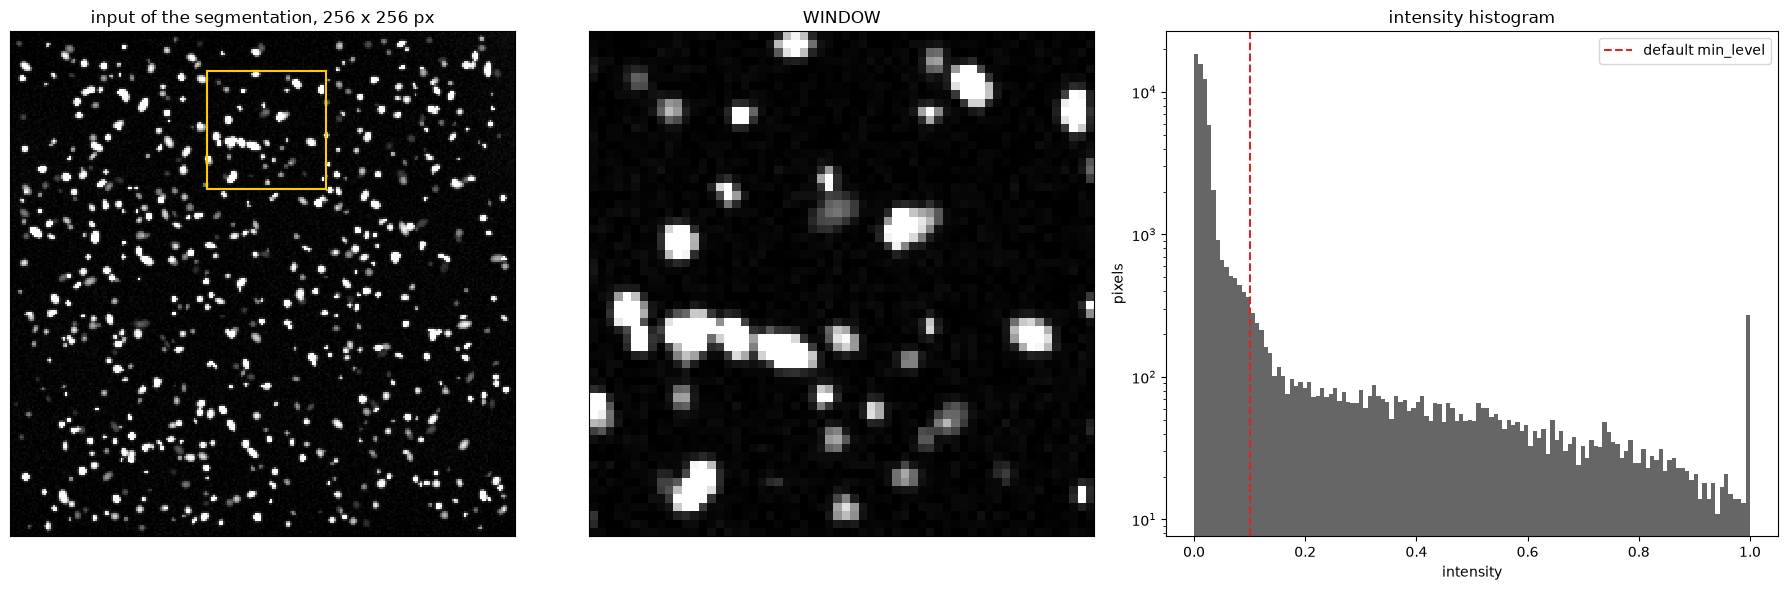

In [3]:
preprocessing = Preprocessing(normalize="full scale", crop=None, blur=0.0)
image = preprocess(raw, full_scale, preprocessing)

WINDOW = (slice(20, 80), slice(100, 160))   # (rows, columns)
VMAX = 0.6

fig, axes = plt.subplots(1, 3, figsize=(18, 6), gridspec_kw={"width_ratios": [1, 1, 1.2]})
show_image(axes[0], image, f"input of the segmentation, {image.shape[0]} x {image.shape[1]} px", VMAX)
mark_window(axes[0], WINDOW)
show_image(axes[1], image[WINDOW], "WINDOW", VMAX)
axes[2].hist(image.ravel(), bins=128, log=True, color="0.4")
axes[2].axvline(Parameters().min_level, color="C3", linestyle="--", label="default min_level")
axes[2].set_xlabel("intensity")
axes[2].set_ylabel("pixels")
axes[2].legend()
axes[2].set_title("intensity histogram")
fig.tight_layout()

## 3. A first segmentation with the defaults

`segment_image` runs all steps on the whole image. The result holds the label
image `labels` (0 for the background, 1, 2, ... for the segments) on the
grid that was segmented. The right panel draws the boundaries on the original
pixels. Yellow edges border the background. Red edges separate neighbors
that the forest cut apart (steps 1–2), and blue edges separate the lobes of an
8-shaped outline (step 4).

516 segments


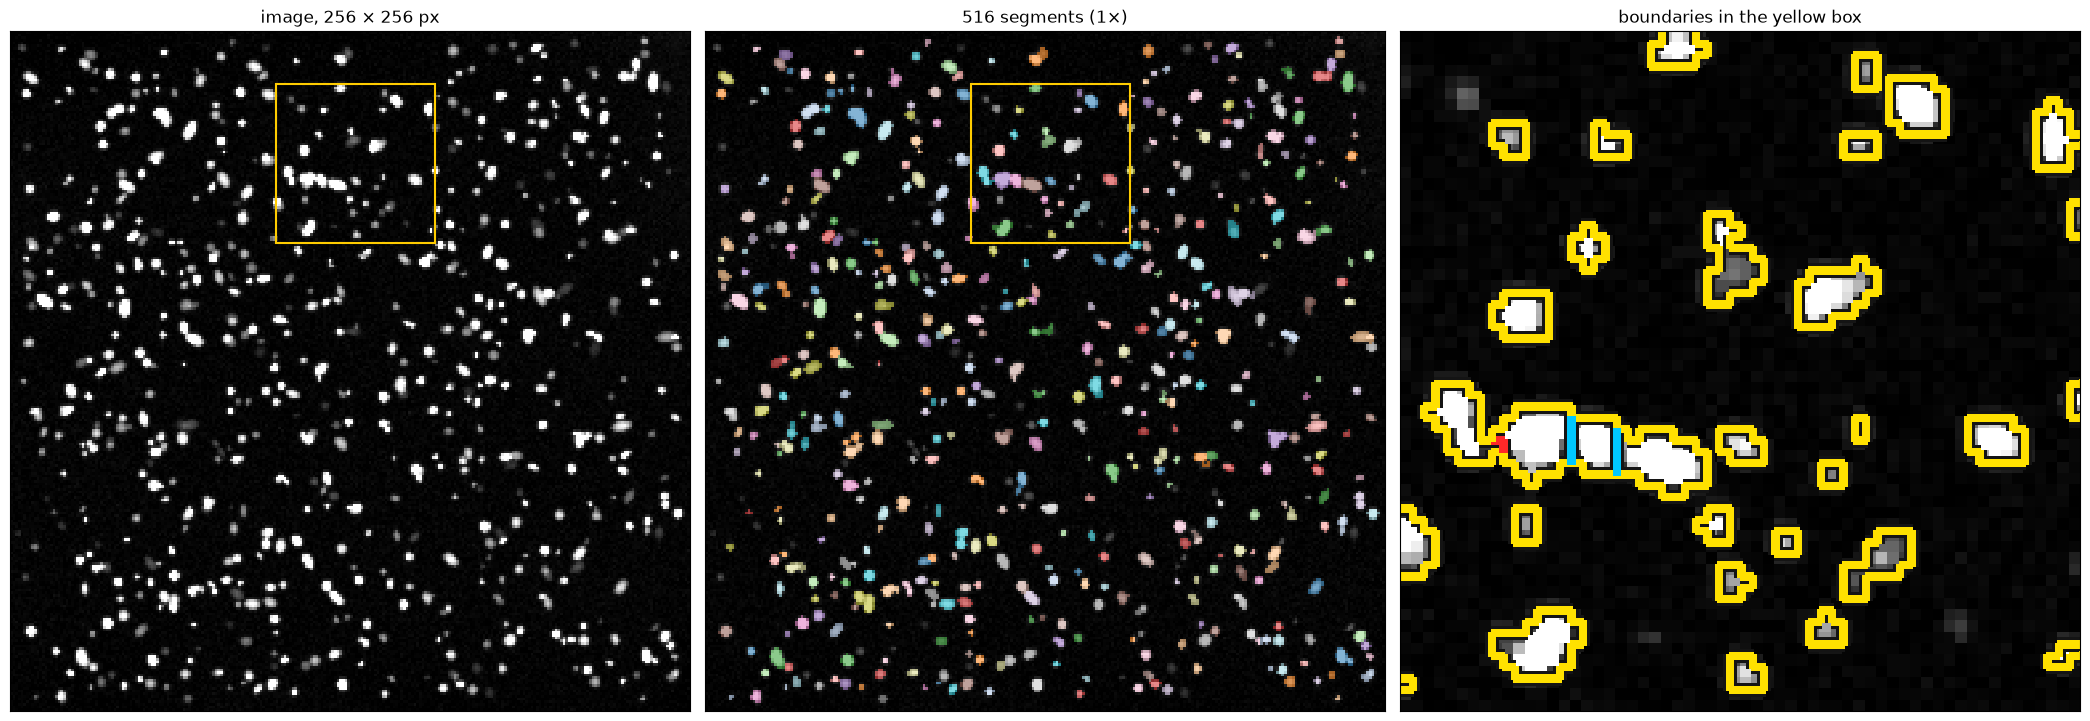

In [4]:
segmentation_1x = segment_image(image, Parameters())
print(f"{segmentation_1x.n_segments} segments")
fig = plot_segmentation(image, segmentation_1x, window=WINDOW, vmax=VMAX)

## 4. Resolution: when to upsample

At the original resolution, the outline of a droplet 3 px across is a
staircase of a few pixels. Its shape is then mostly pixel corners, and a waist
between two touching droplets that is narrower than a pixel cannot show.
`upsample=4` segments a 4× finer image instead: each fine pixel is a
Gaussian-weighted average of the original pixels around it. Its level sets
are smooth curves, so the outlines become smooth and sub-pixel waists show.

**Rule of thumb.** Upsample (`upsample=4`) if the droplets are less than
about 6 px across, or if touching droplets are merged at 1×. Droplets of 10 px
and more need no upsampling.

The parameters stay the same, because lengths are in original pixels and
intensities don't change. The price is time: an upsampled image has 16× as
many pixels and is segmented in tiles. For 256 × 256 px this takes about half
a minute on one process; `WORKERS = 4` (first cell) makes it about 3× faster,
with the same result.

`kernel_width` (0.35 original px) is the width of the Gaussian. A narrower
kernel keeps the original pixels visible as blocks. A wider one smooths more
but blurs touching droplets together and lowers small peaks.

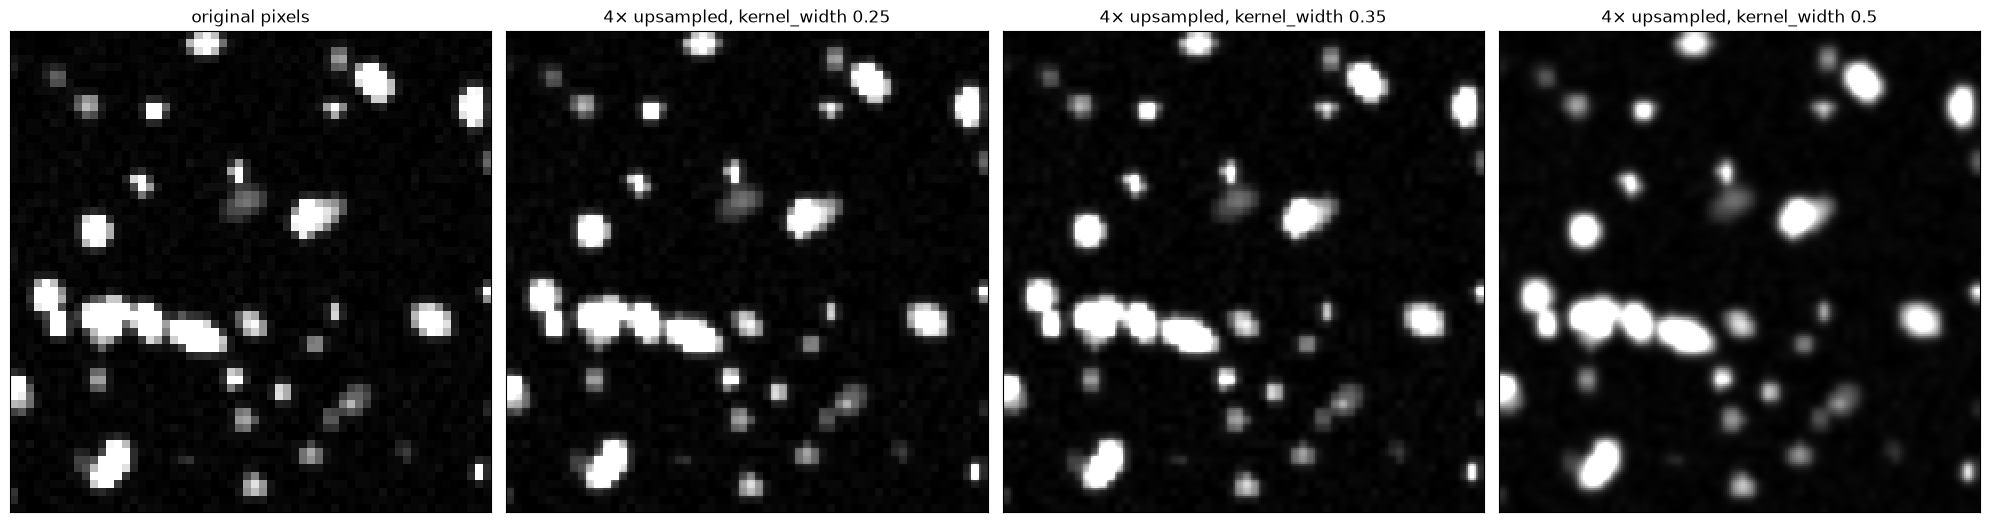

In [5]:
from dropseg import gaussian_upsample

window = image[WINDOW]
fig, axes = plt.subplots(1, 4, figsize=(20, 5.4))
show_image(axes[0], window, "original pixels", VMAX)
for ax, width in zip(axes[1:], (0.25, 0.35, 0.5)):
    show_image(ax, gaussian_upsample(window, 4, width), f"4× upsampled, kernel_width {width}", VMAX)
fig.tight_layout()

The same parameters at both resolutions, drawn on the original pixels. At 4×,
the outlines follow the droplets instead of the pixel grid. Touching droplets
are cut along the valley between them, and a bright droplet is separated from
a dim neighbor that 1× merges with it. The total count changes little: most
droplets are found at both resolutions, but their segments fit better at 4×.

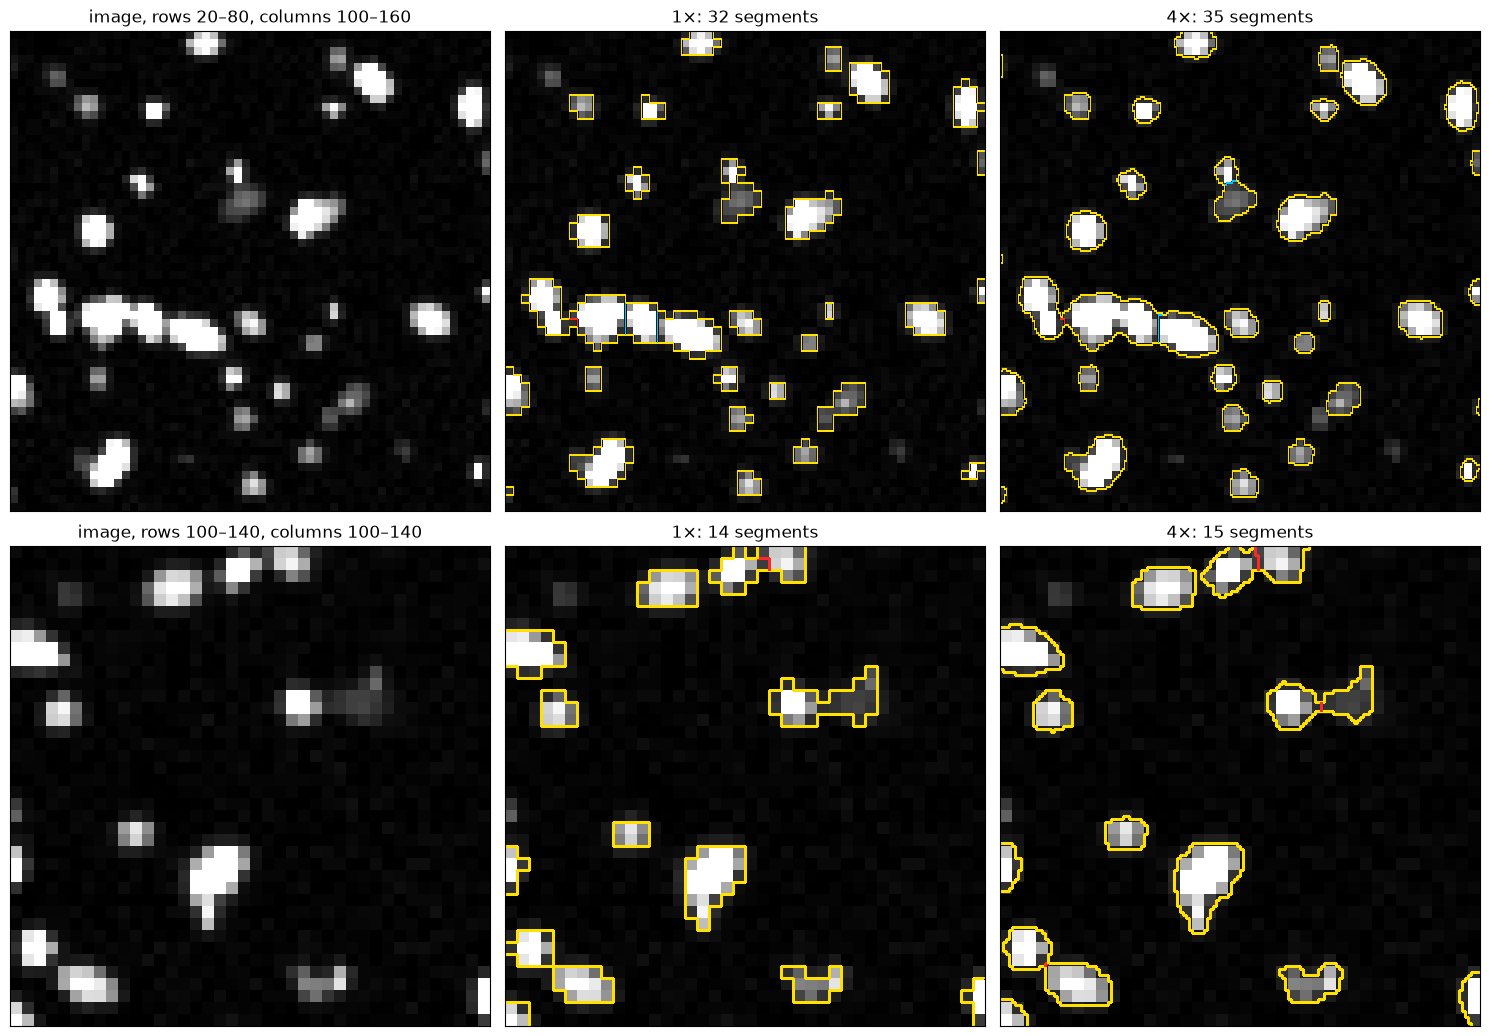

In [6]:
segmentation_4x = segment_image(image, Parameters(upsample=4), WORKERS)
windows = [WINDOW, (slice(100, 140), slice(100, 140))]
fig = plot_resolutions(image, {"1×": segmentation_1x, "4×": segmentation_4x}, windows, vmax=VMAX)

## 5. Tuning the parameters step by step

`Tuner` runs the steps on `WINDOW` (with a margin, so that droplets at its edge
are complete). `tuner.step(name)` shows one step with sliders for its
parameters. Moving a slider updates `tuner.parameters`, so the later steps
start from the values chosen in the earlier ones. Work through the steps in
order. Only the changed step and the later ones are recomputed, which takes
well under a second.

`tuner.compare(name, values)` draws one parameter at several values side by
side. Unlike the sliders, these figures are also visible when the notebook is
only viewed, e.g. on GitHub.

The starting values below are the defaults at 4×, with a little smoothing, a
larger minimal area, outlines taken a little higher (`min_level` 0.15) and
slightly wider waists split (`lobe_waist` 0.8).

In [7]:
parameters = Parameters(
    upsample=4,                          # 1 or 4; see section 4
    kernel_width=0.35,                   # upsampling kernel, original pixels
    min_bar_length=0.2,                  # 1: minimal rise of a peak above its saddle
    split_level=0.3,                     # 2: peaks separating below this are separate droplets
    min_level=0.15,                      # 3, 5: outlines are taken and segments grown down to this level
    convexity_tol=None,                  # 3: off; e.g. 0.4 climbs past messy outlines on a noisy background
    split_lobes=True,                    # 4: split 8-shaped outlines
    smooth_radius=0.3,                   # 6: alpha opening radius, original pixels; None to skip
    min_area=4.0,                        # 7: smallest segment kept, original pixels
    # rarely changed:
    birth_offset=0.1,                    # 3: outlines lie at least 0.1 x min_bar_length above the bar's birth
    lobe_waist=0.8,                      # 4: split if the waist is at most 0.8 x as wide as the lobe
)
tuner = Tuner(image, WINDOW, parameters, vmax=VMAX)

### Step 1: peaks — `min_bar_length`

Every local maximum is the death of a bar. The bar is born at the level where
the peak separates from a brighter neighbor or from the background. The *bar
length* (death minus birth) is how far the peak rises above that saddle.
Peaks with a bar of at least `min_bar_length` are candidate droplets (green).
The red crosses are shorter bars, at least a quarter as long. In the diagram
on the right, bars above the red line are kept.

- Noise peaks or dim haze become droplets: raise `min_bar_length`.
- Faint droplets are missed: lower it, but stay well above the noise.

`upsample` and `kernel_width` are set here too, because they change the image
all later steps work on.

In [8]:
tuner.step("peaks")

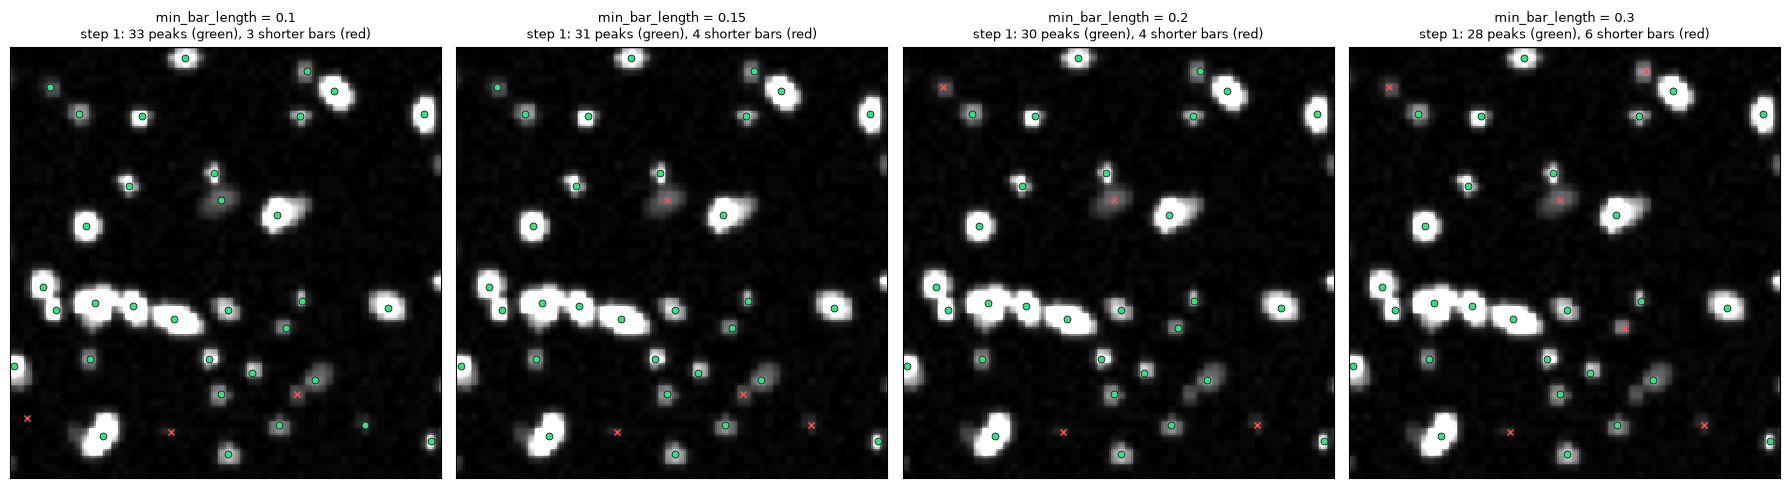

In [9]:
fig = tuner.compare("min_bar_length", [0.1, 0.15, 0.2, 0.3])

### Step 2: branches — `split_level`

Two touching droplets are two peaks whose bars meet at a saddle: the dimmer
peak's bar is born at the saddle level. If that level is below
`split_level`, the two separate low down on their flanks and are two
droplets (colored dots). If it is above, they separate only near the top of
one blob. The dimmer peak (diamond) is then merged into the droplet it splits
off, joined to it by a line. In the diagram, bars left of the dashed line are
separate droplets.

- One blob with two maxima near its top is split in two: lower `split_level`.
- Two touching droplets are merged: raise it.

In [10]:
tuner.step("branches")

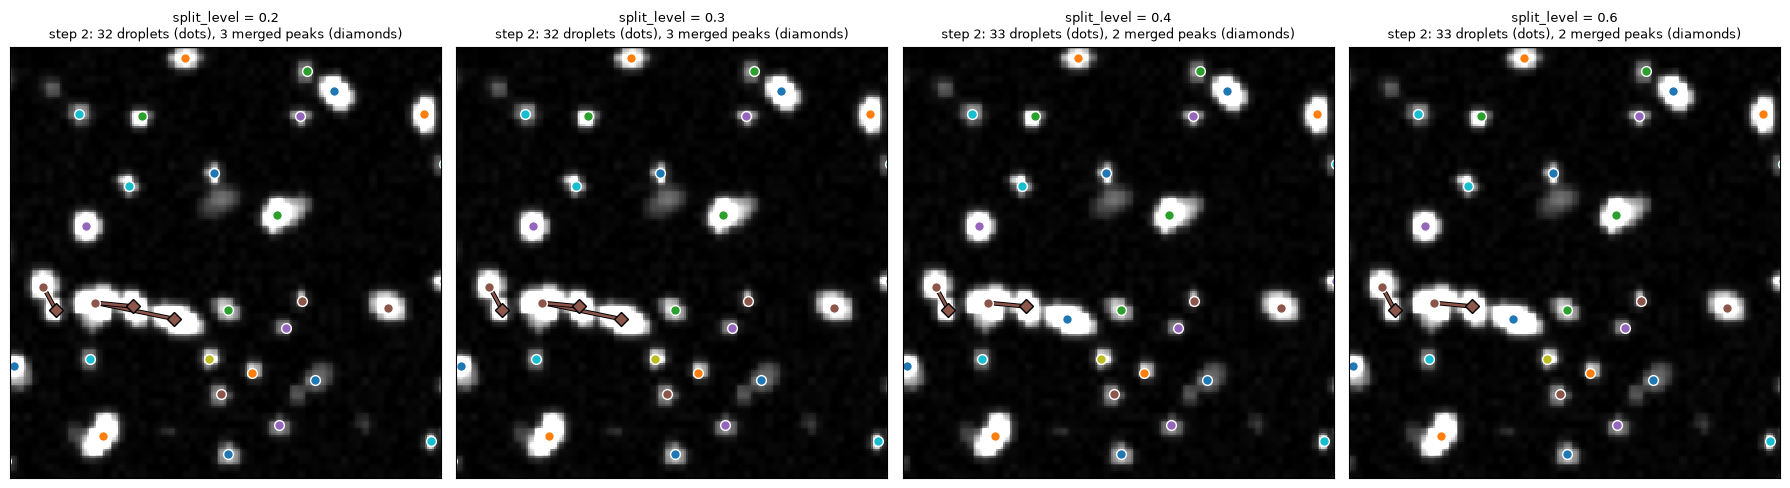

In [11]:
fig = tuner.compare("split_level", [0.2, 0.3, 0.4, 0.6])

### Step 3: outlines — `min_level`

The outline of a droplet is the boundary of the region brighter than
`min_level` around its peak. It is taken higher if the droplet has split off
a neighbor above `min_level` (dash-dotted, after the split). It also lies at
least `birth_offset` × `min_bar_length` above the bar's birth, past the
wiggly outlines just after it (in gray where this decided).

- Outlines reach into the background or into neighbors: raise `min_level`.
- Outlines cut off the dim flanks of the droplets: lower it, but keep it
  above the background (see the histogram in section 2).

`convexity_tol` (off) guards against messy outlines on a noisy background. With
a tolerance of about 0.4 to 0.5, the search climbs to the first outline whose
convex-hull perimeter deficit is at most that, but not past `split_level`.
To try it, use `tuner.step("outlines", extra=("convexity_tol",))`.

In [12]:
tuner.step("outlines")

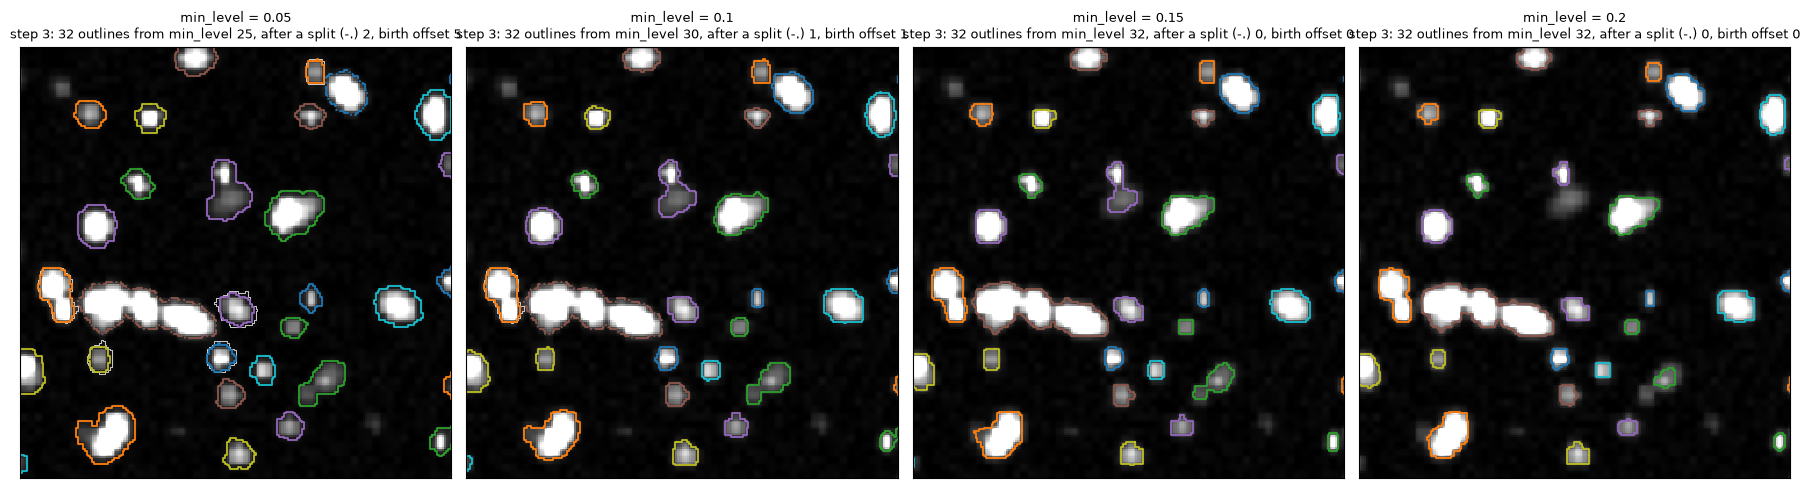

In [13]:
fig = tuner.compare("min_level", [0.05, 0.1, 0.15, 0.2])

### Step 4: lobes — `split_lobes`, `lobe_waist`

Two droplets without a valley between them share one bar, but their outline
is 8-shaped. The alpha filtration of the outline's vertices (a point cloud)
shows the waist. Its interior hole splits in two when the alpha radius
reaches s, half the width of the waist. The split-off part then fills at ρ,
about the radius of its lobe. The ratio s/ρ says how much of an 8 the outline
is: about 1 for no constriction, near 0 for two lobes touching at a point.
The outline is split if s/ρ ≤ `lobe_waist` (0.75 by default, 0.8 here). The ratio is purely
geometric, so it doesn't depend on the size of the droplet or the resolution.

A lobe has no bar of its own, so step 1 is repeated for it. A lobe is a
droplet only if its brightest pixel rises at least `min_bar_length` above the
birth of the outline's bar. A dimmer lobe (red dashes) is cut off like the
others and then removed, usually a dim tail hanging off a droplet.

- Single elongated droplets are cut in two: lower `lobe_waist`.
- Clear 8-shapes stay whole: raise it.

The gallery below the view shows every split in the window, the weakest
(largest s/ρ) first.

In [14]:
tuner.step("lobes")

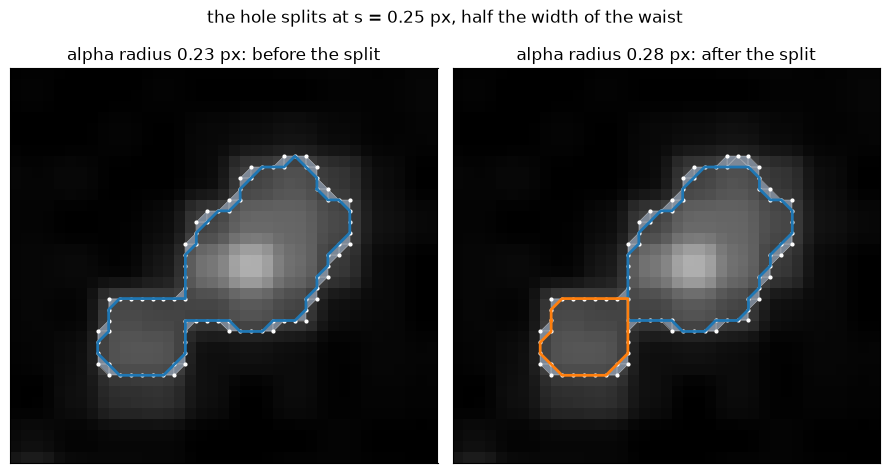

In [15]:
# The alpha complex of the split with the narrowest waist in the window, before and after its hole splits.
splits = [split for split in tuner.stages.lobes(tuner.parameters).values() if split.lobes]
narrowest = min(splits, key=lambda split: max(bar.birth / bar.death for bar in split.lobe_bars))
fig = plot_waist(tuner.stages.image(tuner.parameters), narrowest, tuner.parameters.upsample, vmax=VMAX)

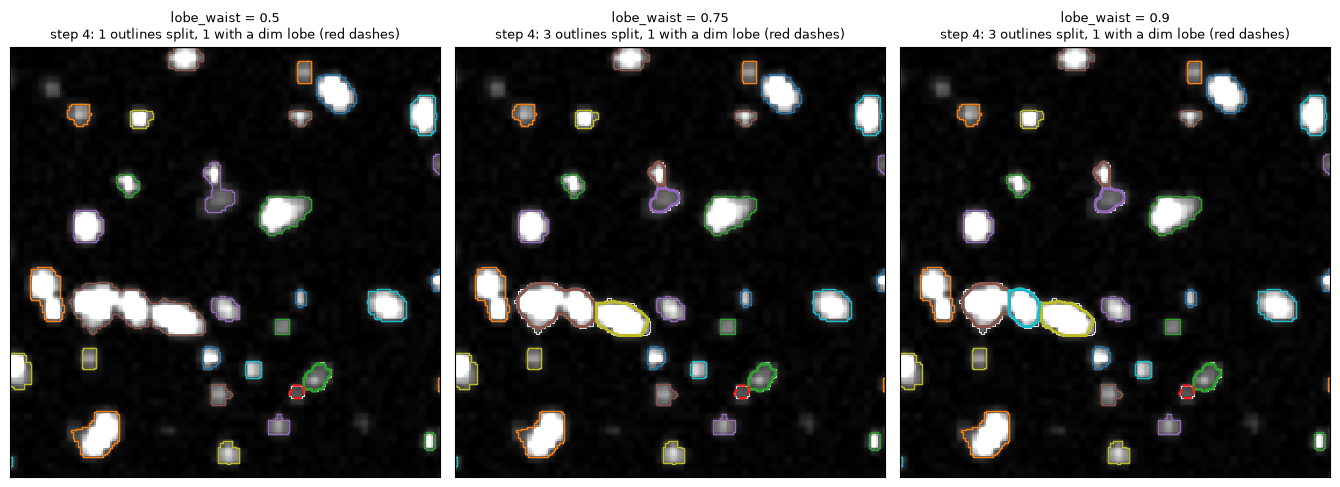

In [16]:
fig = tuner.compare("lobe_waist", [0.5, 0.75, 0.9])

### Step 5: flooding

An outline taken above `min_level` (after a split from a neighbor, or lifted
by the birth offset) leaves out its flanks. Every segment grows into the
pixels around it from bright to dark, down to `min_level` and no further. Two
growing segments meet in the valley between them, so one level decides both
where outlines are taken and how far segments reach. This step has no
parameter of its own: to include more of the dim flanks, lower `min_level`
in step 3.

In [17]:
tuner.step("flooding")

### Step 6: smoothing — `smooth_radius`

An alpha opening of radius `smooth_radius` (original pixels) removes
protrusions narrower than about twice the radius from every segment. It is
meant for upsampled images: at 1×, radii around 1 px remove whole small
droplets. `None` (the slider at 0) turns it off.

An opening can cut a segment with a narrow neck into pieces. If it cuts a
segment into several pieces of at least `min_area`, the radius is too large.
The view then says so in red, and `segment_image` warns.

In [18]:
tuner.step("smoothing")

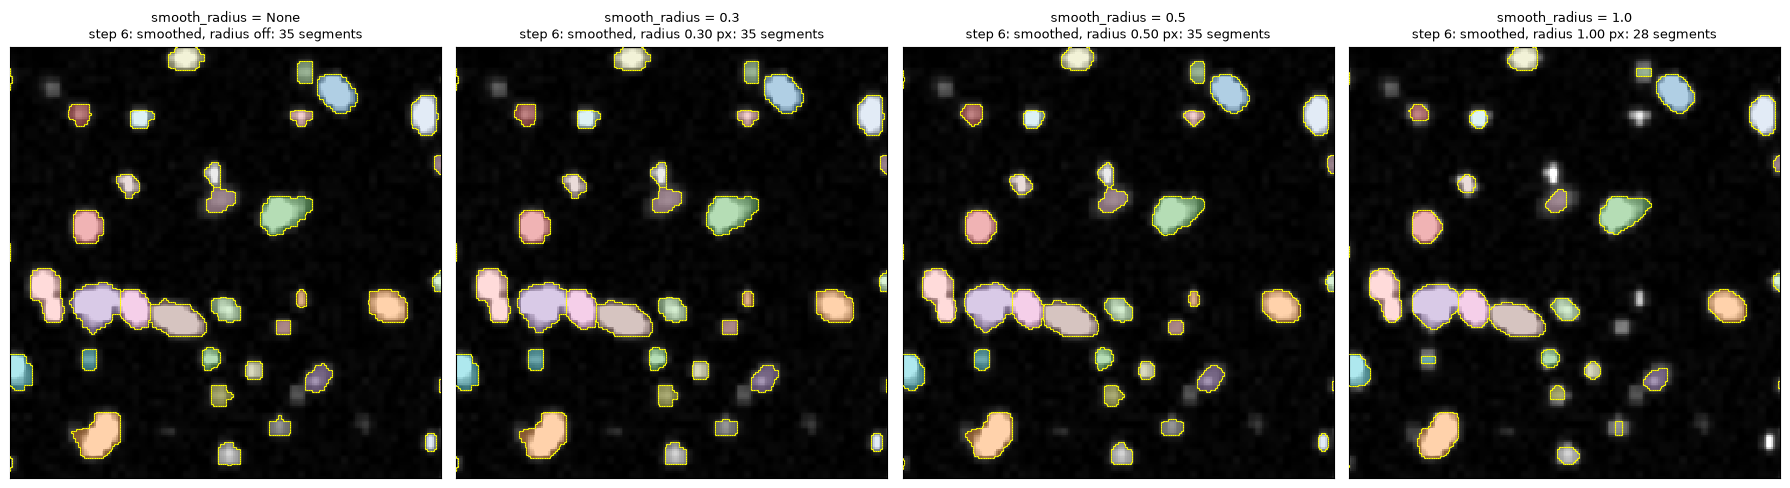

In [19]:
fig = tuner.compare("smooth_radius", [None, 0.3, 0.5, 1.0])

### Step 7: filter — `min_area`

Pieces smaller than `min_area` original pixels are dropped (red). These are
whole segments, or parts of a segment that the smoothing cut off.
Brightness was already checked in step 1 for every droplet and in step 4 for
every lobe, so it is not checked again.

In [20]:
tuner.step("filter")

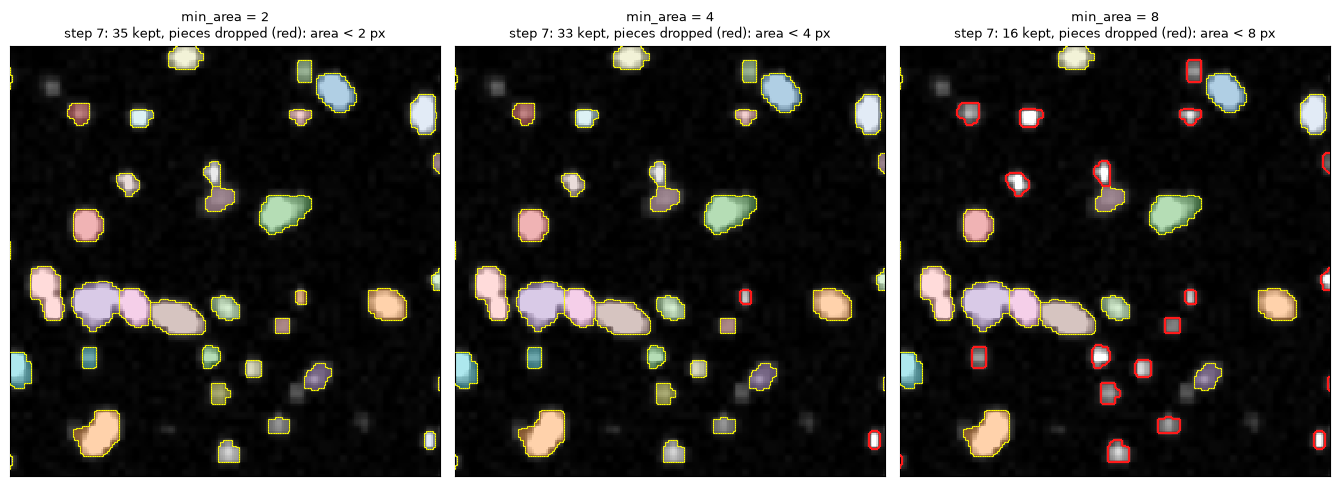

In [21]:
fig = tuner.compare("min_area", [2, 4, 8])

## 6. Segment the whole image

The sliders change only `tuner.parameters`. The cell below uses the values
written in the *parameters* cell of section 5, unless `USE_TUNED = True`. To
keep slider values for later sessions, copy the printed `tuned` values into
that cell. Rerunning that cell starts a new tuner and forgets the slider
values.

Droplets touching the border of the image get no segment, because the
forest treats everything beyond the border as brighter than the image.

tuned:   Parameters(upsample=4, kernel_width=0.35, min_bar_length=0.2, split_level=0.3, min_level=0.15, convexity_tol=None, split_lobes=True, smooth_radius=0.3, min_area=4.0, birth_offset=0.1, lobe_waist=0.8)
in code: Parameters(upsample=4, kernel_width=0.35, min_bar_length=0.2, split_level=0.3, min_level=0.15, convexity_tol=None, split_lobes=True, smooth_radius=0.3, min_area=4.0, birth_offset=0.1, lobe_waist=0.8)


463 segments


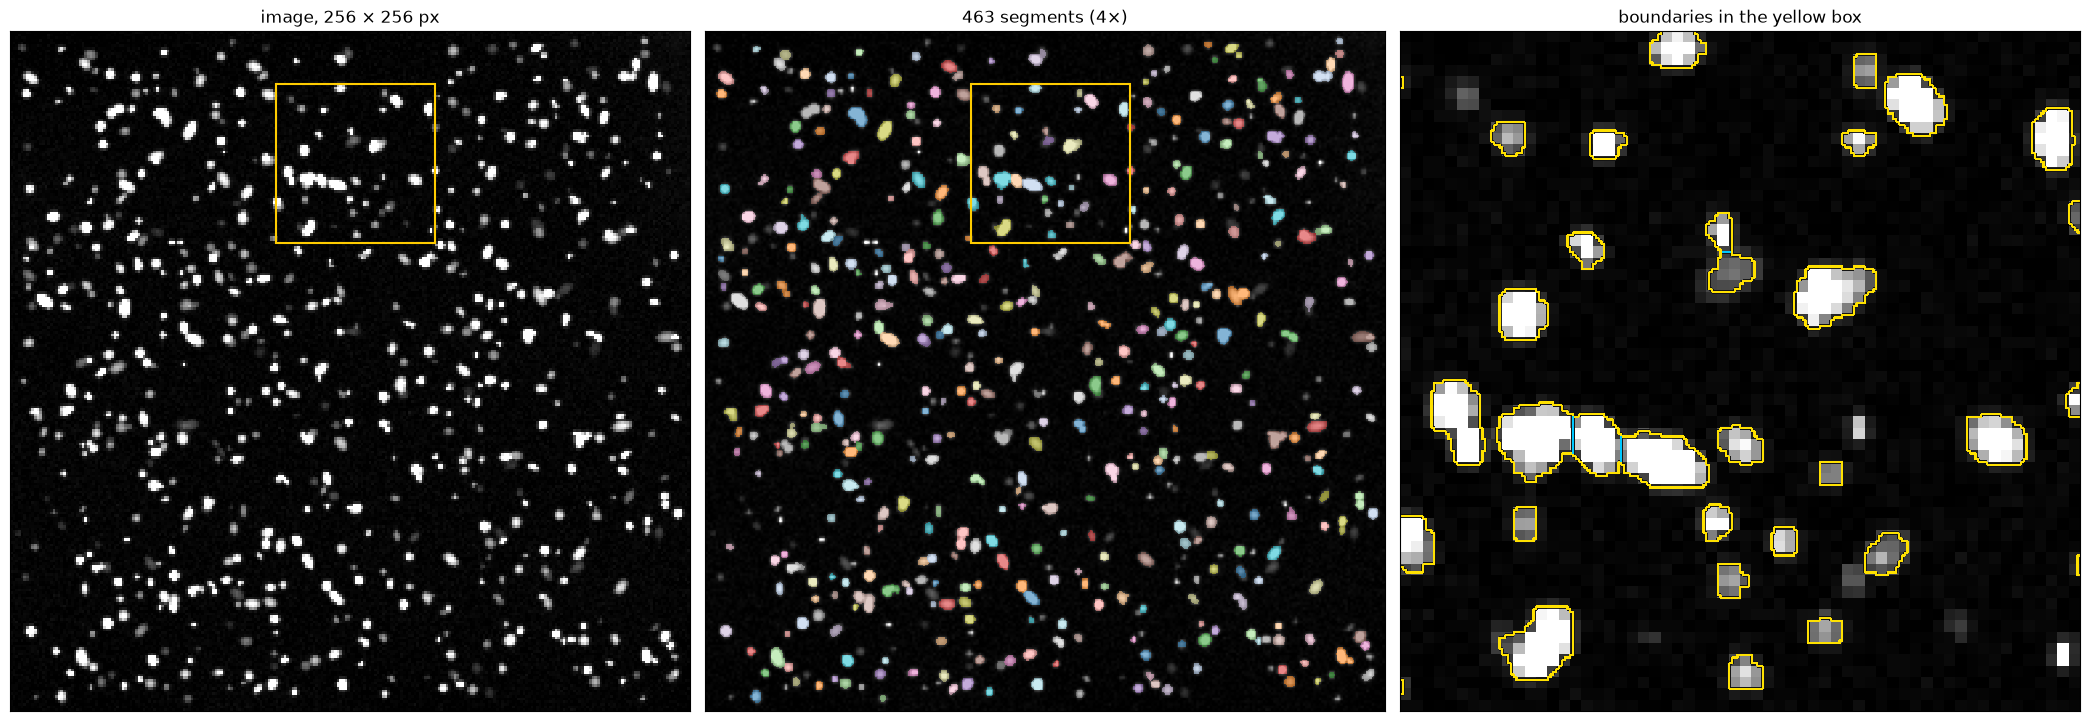

In [22]:
USE_TUNED = False                        # True: use the slider values of section 5

print("tuned:  ", tuner.parameters)
print("in code:", parameters)
chosen = tuner.parameters if USE_TUNED else parameters

segmentation = segment_image(image, chosen, WORKERS)
print(f"{segmentation.n_segments} segments")
fig = plot_segmentation(image, segmentation, window=WINDOW, vmax=VMAX)

## 7. Save the results

`save_results` writes into a folder, named after the image:

- `_labels.tif`: the label image on the original pixels, 0 for the background.
  It opens in Fiji or napari as a label image. Upsampled labels are reduced to
  the original pixels by majority, and also saved on the fine grid as
  `_labels_4x.tif`.
- `_segments.csv`: area, equivalent radius, centroid and mean and maximal
  intensity of every segment, in original pixels.
- `_boundaries.png`: the image with the segment boundaries, every original
  pixel drawn as `scale` × `scale` pixels, for zooming in. The colors are as
  in section 3.
- `_parameters.json`: the parameters and the preprocessing.

In [23]:
from pathlib import Path

written = save_results("results", Path(PATH).stem, image, segmentation, chosen, preprocessing, scale=8, vmax=VMAX)
for path in written:
    print(f"{path}  ({path.stat().st_size / 1e6:.1f} MB)")

results/simulated_puncta_labels.tif  (0.1 MB)
results/simulated_puncta_segments.csv  (0.0 MB)
results/simulated_puncta_boundaries.png  (0.3 MB)
results/simulated_puncta_parameters.json  (0.0 MB)
results/simulated_puncta_labels_4x.tif  (2.1 MB)


## 8. The same from the command line

Once the parameters are chosen, more images can be segmented without a
notebook. Every parameter is an option, and `--parameters` reads a saved
`_parameters.json`, so the run above is repeated by:

```sh
python -m dropseg example_data/simulated_puncta.png --parameters results/simulated_puncta_parameters.json --out results
```

To segment a whole folder of images with explicit parameters:

```sh
python -m dropseg my_images/ --upsample 4 --smooth-radius 0.3 --min-area 4 --out results
```

`python -m dropseg --help` lists all options. The notebook
[example_large_image.ipynb](example_large_image.ipynb) applies the
segmentation to a large simulated image with bigger droplets.